# Lecture 21: Causality — the Randomized Controlled Experiment
v.ekc

Using a **Random Controlled Trial** experimental design for an A/B Hypothesis test, we randomly assign individuals to groups. The random assignment removes the possibility of confounding variables and so we are able to conclude the groups are different *and* that there is causation.

**Today's sections:**
1. The botox RCT
2. Testing the hypothesis
3. Discussion — Super Soda

In [1]:
from datascience import *
%matplotlib inline
path_data = '../../../assets/data/'
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import warnings
warnings.filterwarnings("ignore")

---
## 1. The Botox RCT 💉

Thirty-one back-pain patients are randomly assigned to a control or a treatment group. The control group was given saline and the treatment group was given botox.

Individuals reported pain relief.

In [2]:
botox = Table.read_table('bta.csv')
botox.show()

Group,Result
Control,1
Control,1
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0


In [3]:
# How many people experienced pain relief in each group?
botox.group('Group',sum)

Group,Result sum
Control,2
Treatment,9


As proportions now: on a 0/1 column, the average is exactly the fraction relieved:

In [4]:
# What proportion of people experienced pain relief in each group?
botox.group('Group',np.average)

Group,Result average
Control,0.125
Treatment,0.6


### Try It 1: The groups themselves 😊

1. For `Control` or `Treatment`, what count of people experienced back pain relief?

2. What proportion of all 31 patients reported relief, ignoring groups?

3. The two group proportions above differ a lot. Why can't we declare "botox works" right here?

In [20]:
# 1. grid of group versus Result

botox.pivot('Result', 'Group')


Group,0.0,1.0
Control,14,2
Treatment,6,9


In [21]:
# 2. overall relief proportion
sum(botox.column('Result')) / botox.num_rows

0.35483870967741937

*3. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*`group` alone counts rows; on a 0/1 column, `sum` counts successes and `average` gives the proportion.*

```python
# 1.
botox.pivot('Result', 'Group')

# 2.
sum(botox.column('Result')) / botox.num_rows
```

*3. Chance. Even if botox did nothing, a random split of 31 people would rarely spread the relieved patients evenly. The question is whether a gap this big is more than chance, and that is exactly what the test below answers.*

</details>

---
## 2. Testing the Hypothesis

> **Null:** botox does nothing, the observed difference is just the luck of random assignment.
> **Alternative:** botox increases the chance of pain relief.
> **Test statistic:** difference in proportion relieved (treatment − control); *big* values favor the alternative.

(Writing tips: make the null precise enough to simulate, and say which direction of the statistic favors the alternative.)

We load in our helped functions! The real observed difference first, then one difference from a shuffled world (run it a few times):

In [7]:
# calculate the difference of means
def difference_of_means(table, label, group_label):
    """Takes: name of table, column label of numerical variable,
    column label of group-label variable
    Returns: Difference of means of the two groups"""
    
    #table with the two relevant columns
    reduced = table.select(label, group_label)  
    
    # table containing group means
    means_table = reduced.group(group_label, np.average)
    # array of group means
    means = means_table.column(1)
    
    return means.item(1) - means.item(0)

In [8]:
# calculate ONE statistic
#  shuffle the means and then calculate the difference
#  this function calls the previously defined function 'difference_of_means'

def one_simulated_difference(table, label, group_label):
    """Takes: name of table, column label of numerical variable,
    column label of group-label variable
    Returns: Difference of means of the two groups after shuffling labels"""
    
    # array of shuffled labels
    shuffled_labels = table.sample(with_replacement = False).column(group_label)
    
    # table of numerical variable and shuffled labels
    shuffled_table = table.select(label).with_column('Shuffled Label', shuffled_labels)
    
    return difference_of_means(shuffled_table, label, 'Shuffled Label')   

In [9]:
observed_diff = difference_of_means(botox, 'Result', 'Group')
observed_diff

0.475

In [10]:
one_simulated_difference(botox, 'Result', 'Group')

0.08750000000000002

Now 10,000 shuffled worlds:

In [11]:
simulated_diffs = make_array()

for i in np.arange(10000):
    sim_diff = one_simulated_difference(botox, 'Result', 'Group')
    simulated_diffs = np.append(simulated_diffs, sim_diff)

Where does the observed difference land among the shuffled ones???

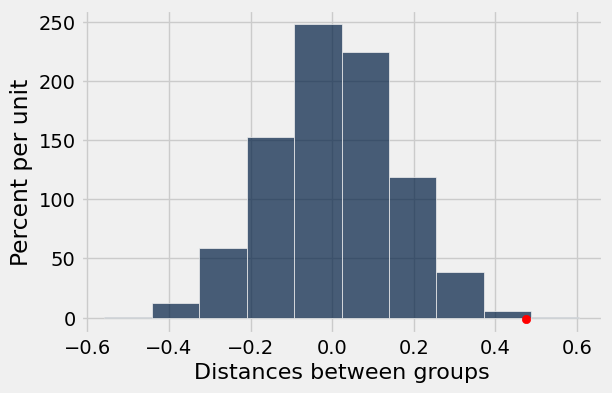

In [22]:
col_name = 'Distances between groups'
Table().with_column(col_name, simulated_diffs).hist(col_name)
plots.scatter(observed_diff,-0.01, c='red');

In [13]:
# p-value
sum(simulated_diffs >= observed_diff)/len(simulated_diffs)

0.0073000000000000001

### Try It 2: Read the simulation 😊

1. How many of the 10,000 shuffled differences came out **at least as large** as the observed difference? (A count, not a fraction.)

2. What is the largest difference any shuffled world produced?

3. In one sentence: what does the p-value above say about the null hypothesis?

In [14]:
# 1. count at or above observed


In [15]:
# 2. largest shuffled difference


*3. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*The p-value numerator, and one extreme value, both straight from the array.*

```python
# 1.
sum(simulated_diffs >= observed_diff)

# 2.
max(simulated_diffs)
```

*3. In worlds where botox does nothing, a gap as large as the observed 0.475 almost never happens, so chance is a poor explanation and the data favor the alternative.*

</details>

**Conclusion**: The test favors the alternative hypothesis over the null since the p-value, by convention is less than $0.05$ . The result is statistically significant. Therefore, the data supports the hypothesis that the treatment is doing something. Additionally, because the trials were randomized, the test is evidence that the treatment *causes* the difference. The random assignment of patients to the two groups **ensures that there is no confounding variable that could affect the conclusion of causality**!

> **Because assignment was random**, "not chance" that means the only difference between the groups was the treatment: this is evidence of *causation*, not just association.

---
## 3. Discussion: Super Soda 🥤

In a taste test, 91 of 200 tasters prefer Super Soda over its rival. The company claims a 50/50 split. Before scrolling: what are the null, alternative, and test statistic?

### Try It 3: Set up the test 🏷️

1. Write the null hypothesis, the alternative, and the test statistic in the cell below, then check against the simulation.

*1. Your answer: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Null: tasters are 50/50, like fair-coin tosses; 91 is chance. Alternative: fewer than half prefer Super Soda. Test statistic: number of "heads" (Super Soda preferences) in 200; small values favor the alternative.*

</details>

Now simulate: one taste test under the null is just 200 coin flips:

In [16]:
def simulate_one_count(sample_size):
    return np.count_nonzero(np.random.choice(['H', 'T'], sample_size) == 'H')
simulate_one_count(200)

102

In [17]:
num_simulations = 10000
counts = make_array()
for i in np.arange(num_simulations):
    counts = np.append(counts, simulate_one_count(200))

Histogram the 10,000 counts and mark the observed 91:

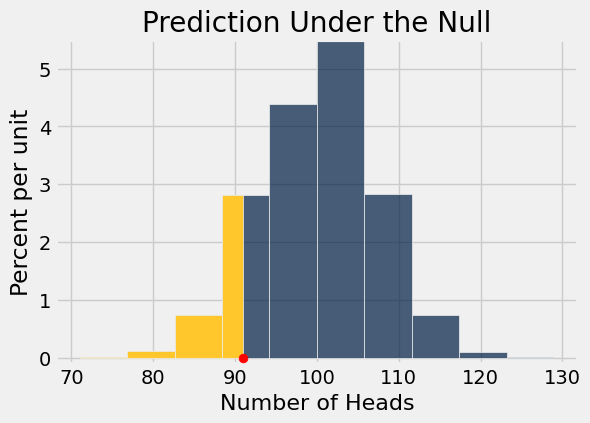

In [18]:
trials = Table().with_column('Number of Heads', counts)
trials.hist(right_end=91)
plots.ylim(-0.001, 0.055)
plots.scatter(91, 0, color='red', s=40, zorder=3)
plots.title('Prediction Under the Null');

The p-value: the fraction of fair-split worlds at or below 91:

In [19]:
np.count_nonzero(counts <= 91)/len(counts)

0.1136

> **Verdict:** p ≈ 0.11, more than one in ten fair-split worlds produce a result this low. By the 5% convention, we *can't* reject the null. Compare with botox: same recipe, different conclusion, and both are useful answers.

---
> **Today's takeaway:** random assignment + hypothesis test = causal evidence; and a big p-value is a finding too, not a failure.

## Appendix — Quick Reference

Full `datascience` docs: [data8.org/datascience](https://data8.org/datascience/)

### Minimal template — RCT test
```python
observed = difference_of_means(t, value_label, group_label)
# shuffle labels 10,000 times, then:
p_value = sum(simulated >= observed) / len(simulated)
```